# SmartFactory AI - Etape 4 : Classification supervisée
Objectif : prédire `Machine_failure` et comparer plusieurs algorithmes, **avec les variables originales** et **avec les composantes PCA**.

Prérequis : `train.csv`, `test.csv`, `train_pca.csv`, `test_pca.csv` dans `data/`.

Gestion du déséquilibre (3,4 % de pannes) : `class_weight="balanced"` quand le modèle le permet, puis ajustement du seuil de décision.

## 1. Imports, chemins et chargement

In [2]:
import time
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from pathlib import Path

from sklearn.base import clone
from sklearn.model_selection import StratifiedKFold, cross_validate, cross_val_predict, RandomizedSearchCV
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, average_precision_score, confusion_matrix,
                             ConfusionMatrixDisplay, RocCurveDisplay, PrecisionRecallDisplay,
                             precision_recall_curve, classification_report)

sns.set_theme(style="whitegrid")

BASE = Path.cwd()
if not (BASE / "data").exists():
    BASE = BASE.parent
DATA, MODELS = BASE / "data", BASE / "models"
print("Projet :", BASE)

train, test = pd.read_csv(DATA / "train.csv"), pd.read_csv(DATA / "test.csv")
train_pca, test_pca = pd.read_csv(DATA / "train_pca.csv"), pd.read_csv(DATA / "test_pca.csv")

X_train, y_train = train.drop(columns="target"), train["target"]
X_test, y_test = test.drop(columns="target"), test["target"]
Xp_train, Xp_test = train_pca.drop(columns="target"), test_pca.drop(columns="target")

print("Variables originales :", X_train.shape[1], "| composantes PCA :", Xp_train.shape[1])
print("Taux de pannes train / test :", round(y_train.mean()*100, 2), "% /", round(y_test.mean()*100, 2), "%")

Projet : c:\Users\ghait\Desktop\Projet Python
Variables originales : 9 | composantes PCA : 5
Taux de pannes train / test : 3.39 % / 3.4 %


## 2. Définition des modèles
| Modèle | Gestion du déséquilibre |
|---|---|
| Logistic Regression (baseline) | `class_weight="balanced"` |
| KNN | `weights="distance"` (pas de class_weight disponible) |
| SVM (noyau RBF) | `class_weight="balanced"` |
| Decision Tree | `class_weight="balanced"`, profondeur limitée |
| Random Forest | `class_weight="balanced"` |
| Gradient Boosting (Hist) | `class_weight="balanced"` |

In [3]:
def make_models():
    return {
        "Logistic Regression": LogisticRegression(class_weight="balanced", max_iter=1000, random_state=42),
        "KNN": KNeighborsClassifier(n_neighbors=7, weights="distance"),
        "SVM": SVC(kernel="rbf", class_weight="balanced", probability=True, random_state=42),
        "Decision Tree": DecisionTreeClassifier(max_depth=6, class_weight="balanced", random_state=42),
        "Random Forest": RandomForestClassifier(n_estimators=300, class_weight="balanced",
                                                n_jobs=-1, random_state=42),
        "Gradient Boosting": HistGradientBoostingClassifier(class_weight="balanced", random_state=42),
    }

def get_score(model, X):
    return model.predict_proba(X)[:, 1]

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scoring = {"recall": "recall", "precision": "precision", "f1": "f1",
           "roc_auc": "roc_auc", "pr_auc": "average_precision"}

## 3. Entraînement et évaluation
Pour chaque modèle :
1. **Validation croisée stratifiée (5 plis) sur le train** : estimation fiable et stable.
2. **Entraînement sur tout le train puis évaluation sur le test** : performance finale sur des données jamais vues.

Le SVM est le plus lent (probabilités activées) : compte 1 à 3 minutes pour l'ensemble.

In [4]:
def run_all(Xtr, ytr, Xte, yte, variante):
    rows, fitted = [], {}
    for name, model in make_models().items():
        t0 = time.time()
        cv = cross_validate(clone(model), Xtr, ytr, cv=skf, scoring=scoring, n_jobs=-1)
        model.fit(Xtr, ytr)
        pred, score = model.predict(Xte), get_score(model, Xte)
        rows.append({
            "Modèle": name, "Variante": variante,
            "CV Recall": cv["test_recall"].mean(), "CV F1": cv["test_f1"].mean(),
            "CV PR-AUC": cv["test_pr_auc"].mean(),
            "Accuracy": accuracy_score(yte, pred),
            "Precision": precision_score(yte, pred, zero_division=0),
            "Recall": recall_score(yte, pred),
            "F1": f1_score(yte, pred),
            "ROC-AUC": roc_auc_score(yte, score),
            "PR-AUC": average_precision_score(yte, score),
            "Temps (s)": time.time() - t0,
        })
        fitted[name] = model
        print(f"{variante:10s} | {name:20s} | F1 test = {rows[-1]['F1']:.3f} | {rows[-1]['Temps (s)']:.1f}s")
    return pd.DataFrame(rows), fitted

res_orig, fitted_orig = run_all(X_train, y_train, X_test, y_test, "Originales")

Originales | Logistic Regression  | F1 test = 0.296 | 3.8s
Originales | KNN                  | F1 test = 0.473 | 2.6s
Originales | SVM                  | F1 test = 0.457 | 5.9s
Originales | Decision Tree        | F1 test = 0.528 | 0.1s
Originales | Random Forest        | F1 test = 0.843 | 2.3s
Originales | Gradient Boosting    | F1 test = 0.844 | 2.0s


In [5]:
res_pca, fitted_pca = run_all(Xp_train, y_train, Xp_test, y_test, "PCA")

PCA        | Logistic Regression  | F1 test = 0.161 | 0.1s
PCA        | KNN                  | F1 test = 0.426 | 0.1s
PCA        | SVM                  | F1 test = 0.375 | 4.2s
PCA        | Decision Tree        | F1 test = 0.307 | 0.1s
PCA        | Random Forest        | F1 test = 0.509 | 2.2s
PCA        | Gradient Boosting    | F1 test = 0.570 | 0.6s


## 4. Tableau comparatif

In [6]:
results = pd.concat([res_orig, res_pca], ignore_index=True)
cols = ["Modèle", "Variante", "Accuracy", "Precision", "Recall", "F1", "ROC-AUC", "PR-AUC", "CV F1", "CV PR-AUC"]
table = results[cols].round(3).sort_values(["Variante", "F1"], ascending=[True, False])
display(table)

results.to_csv(DATA / "resultats_classification.csv", index=False)

,Modèle,Variante,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC,CV F1,CV PR-AUC
5,Gradient Boosting,Originales,0.990,0.851,0.838,0.844,0.976,0.893,0.846,0.874
4,Random Forest,Originales,0.990,0.962,0.750,0.843,0.973,0.869,0.852,0.889
3,Decision Tree,Originales,0.950,0.389,0.824,0.528,0.857,0.773,0.554,0.794
1,KNN,Originales,0.976,0.880,0.324,0.473,0.889,0.605,0.420,0.599
2,SVM,Originales,0.925,0.303,0.926,0.457,0.972,0.629,0.462,0.687
0,Logistic Regression,Originales,0.858,0.178,0.882,0.296,0.939,0.434,0.272,0.458
11,Gradient Boosting,PCA,0.963,0.471,0.721,0.570,0.965,0.626,0.590,0.622
10,Random Forest,PCA,0.974,0.711,0.397,0.509,0.956,0.612,0.458,0.637
7,KNN,PCA,0.973,0.769,0.294,0.426,0.878,0.535,0.418,0.524
8,SVM,PCA,0.904,0.241,0.853,0.375,0.959,0.478,0.397,0.542


**Lecture :**
- **Accuracy** : à relativiser, un modèle qui prédit toujours « pas de panne » fait ~96,6 %.
- **Recall / F1 / PR-AUC** : métriques principales.
- **CV F1 proche de F1 test** : le modèle généralise. Un grand écart signale du sur-apprentissage (typique de l'arbre de décision).

### Comparaison graphique : originales vs PCA

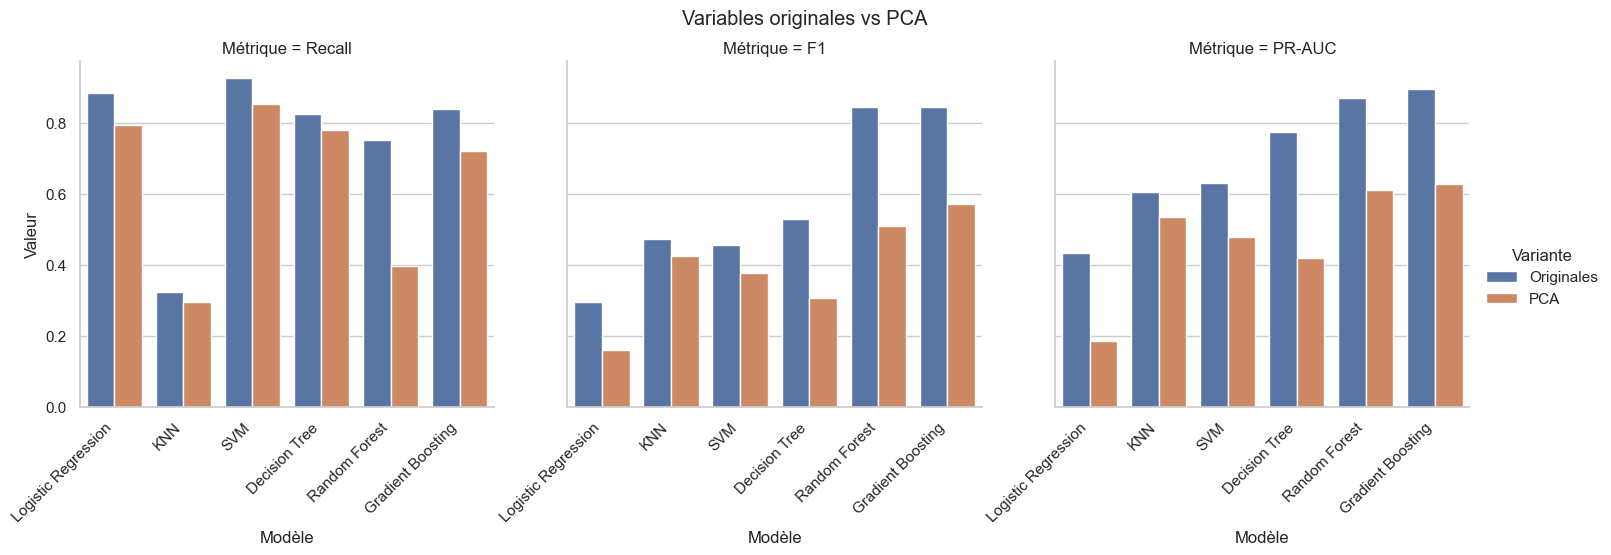

In [7]:
long = results.melt(id_vars=["Modèle", "Variante"], value_vars=["Recall", "F1", "PR-AUC"],
                    var_name="Métrique", value_name="Valeur")

g = sns.catplot(data=long, x="Modèle", y="Valeur", hue="Variante", col="Métrique",
                kind="bar", height=4.5, aspect=1.1)
g.set_xticklabels(rotation=45, ha="right")
g.fig.suptitle("Variables originales vs PCA", y=1.03)
plt.show()

## 5. Matrices de confusion (variables originales)

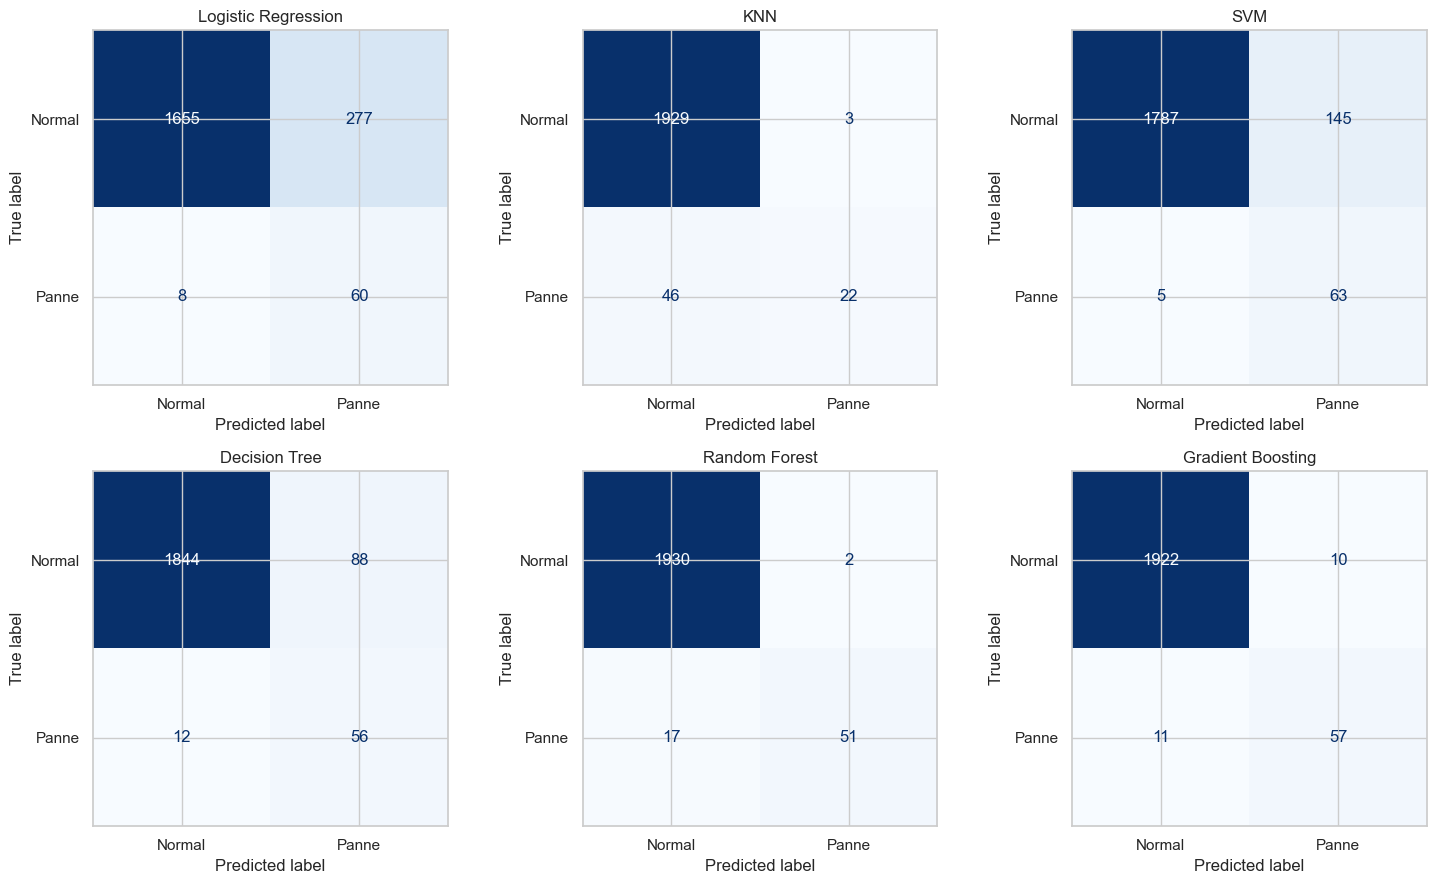

In [8]:
fig, axes = plt.subplots(2, 3, figsize=(15, 9))
for ax, (name, model) in zip(axes.ravel(), fitted_orig.items()):
    ConfusionMatrixDisplay.from_predictions(y_test, model.predict(X_test), ax=ax,
                                            display_labels=["Normal", "Panne"], colorbar=False, cmap="Blues")
    ax.set_title(name)
plt.tight_layout()
plt.show()

## 6. Courbes ROC et Precision-Recall (variables originales)

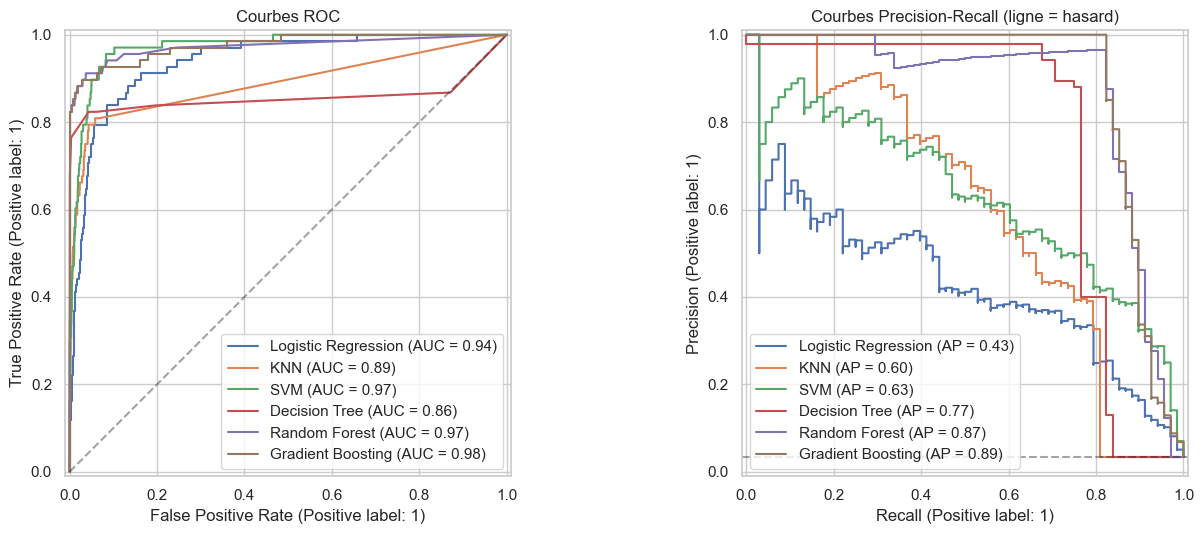

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
for name, model in fitted_orig.items():
    s = get_score(model, X_test)
    RocCurveDisplay.from_predictions(y_test, s, name=name, ax=axes[0])
    PrecisionRecallDisplay.from_predictions(y_test, s, name=name, ax=axes[1])
axes[0].plot([0, 1], [0, 1], "k--", alpha=0.4)
axes[0].set_title("Courbes ROC")
axes[1].axhline(y_test.mean(), color="k", linestyle="--", alpha=0.4)
axes[1].set_title("Courbes Precision-Recall (ligne = hasard)")
plt.tight_layout()
plt.show()

## 7. Optimisation du Random Forest
Recherche aléatoire d'hyperparamètres, optimisée sur la **PR-AUC** (la plus adaptée à une classe rare). Si un autre modèle est meilleur dans ton tableau, remplace simplement le modèle de base ci-dessous.

In [10]:
param_dist = {
    "n_estimators": [200, 300, 500],
    "max_depth": [6, 8, 10, 14, None],
    "min_samples_leaf": [1, 2, 4, 8],
    "min_samples_split": [2, 5, 10],
    "max_features": ["sqrt", "log2", 0.5],
}
search = RandomizedSearchCV(
    RandomForestClassifier(class_weight="balanced", n_jobs=-1, random_state=42),
    param_dist, n_iter=20, scoring="average_precision", cv=skf, random_state=42, n_jobs=1, verbose=1)
search.fit(X_train, y_train)

rf_tuned = search.best_estimator_
print("Meilleurs paramètres :", search.best_params_)
print("PR-AUC CV :", round(search.best_score_, 4))

s_t = get_score(rf_tuned, X_test)
print("\nTest | PR-AUC :", round(average_precision_score(y_test, s_t), 4),
      "| ROC-AUC :", round(roc_auc_score(y_test, s_t), 4),
      "| F1 :", round(f1_score(y_test, rf_tuned.predict(X_test)), 4))

Fitting 5 folds for each of 20 candidates, totalling 100 fits
Meilleurs paramètres : {'n_estimators': 200, 'min_samples_split': 2, 'min_samples_leaf': 2, 'max_features': 0.5, 'max_depth': 10}
PR-AUC CV : 0.8997

Test | PR-AUC : 0.8821 | ROC-AUC : 0.975 | F1 : 0.8615


## 8. Ajustement du seuil de décision
Le seuil par défaut (0,5) n'est pas optimal avec des classes déséquilibrées. On choisit le seuil qui **maximise le F1** à partir de prédictions **hors-échantillon sur le train** (validation croisée), donc sans regarder le test. Ensuite on l'applique au test.

Seuil optimal (max F1 sur train, hors-échantillon) : 0.503


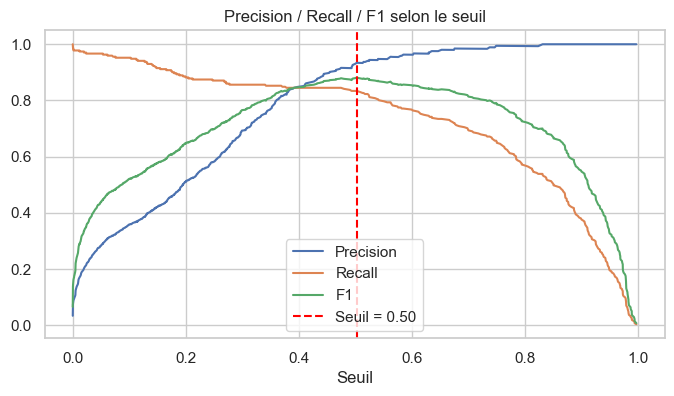

,"Seuil 0,5",Seuil 0.50
Precision,0.903,0.903
Recall,0.824,0.824
F1,0.862,0.862


              precision    recall  f1-score   support

      Normal       0.99      1.00      1.00      1932
       Panne       0.90      0.82      0.86        68

    accuracy                           0.99      2000
   macro avg       0.95      0.91      0.93      2000
weighted avg       0.99      0.99      0.99      2000



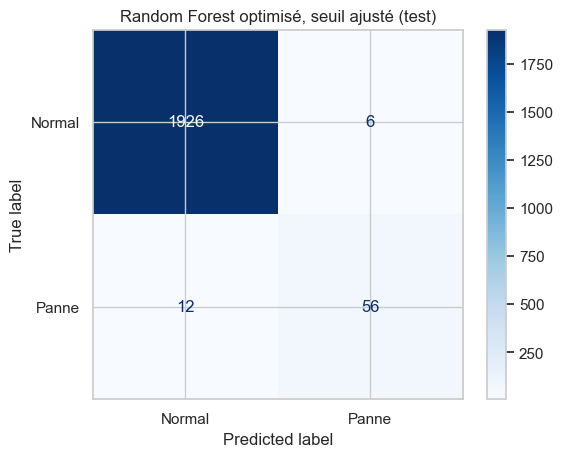

In [11]:
oof = cross_val_predict(clone(rf_tuned), X_train, y_train, cv=skf, method="predict_proba", n_jobs=1)[:, 1]
p, r, thr = precision_recall_curve(y_train, oof)
f1s = 2 * p[:-1] * r[:-1] / (p[:-1] + r[:-1] + 1e-12)
best_thr = float(thr[np.argmax(f1s)])
print("Seuil optimal (max F1 sur train, hors-échantillon) :", round(best_thr, 3))

plt.figure(figsize=(8, 4))
plt.plot(thr, p[:-1], label="Precision")
plt.plot(thr, r[:-1], label="Recall")
plt.plot(thr, f1s, label="F1")
plt.axvline(best_thr, color="red", linestyle="--", label=f"Seuil = {best_thr:.2f}")
plt.xlabel("Seuil"); plt.title("Precision / Recall / F1 selon le seuil")
plt.legend(); plt.show()

pred_def = rf_tuned.predict(X_test)
pred_thr = (get_score(rf_tuned, X_test) >= best_thr).astype(int)

comp = pd.DataFrame({
    "Seuil 0,5": [precision_score(y_test, pred_def), recall_score(y_test, pred_def), f1_score(y_test, pred_def)],
    f"Seuil {best_thr:.2f}": [precision_score(y_test, pred_thr), recall_score(y_test, pred_thr), f1_score(y_test, pred_thr)],
}, index=["Precision", "Recall", "F1"]).round(3)
display(comp)

print(classification_report(y_test, pred_thr, target_names=["Normal", "Panne"]))
ConfusionMatrixDisplay.from_predictions(y_test, pred_thr, display_labels=["Normal", "Panne"], cmap="Blues")
plt.title("Random Forest optimisé, seuil ajusté (test)")
plt.show()

## 9. Sauvegarde pour le dashboard

In [12]:
joblib.dump(fitted_orig, MODELS / "models_original.pkl")
joblib.dump(fitted_pca, MODELS / "models_pca.pkl")
joblib.dump(rf_tuned, MODELS / "rf_tuned.pkl")
joblib.dump({"threshold": best_thr, "best_params": search.best_params_}, MODELS / "rf_tuned_meta.pkl")
print("Modèles sauvegardés dans", MODELS)

Modèles sauvegardés dans c:\Users\ghait\Desktop\Projet Python\models


## Résumé à retenir pour le rapport
1. Validation croisée stratifiée sur le train + évaluation finale sur un test jamais vu.
2. Le déséquilibre est traité avec `class_weight="balanced"` puis par l'ajustement du seuil.
3. Métriques principales : Recall, F1, PR-AUC (l'accuracy est trompeuse).
4. Comparaison originales vs PCA : discute pourquoi la PCA n'améliore (probablement) pas les résultats : les variables sont déjà peu nombreuses, et la PCA mélange les variables et fait perdre des seuils précis sur `Torque`, `Tool_wear`, etc.
5. Modèles à arbres (Random Forest, Gradient Boosting) généralement meilleurs ici : les pannes sont définies par des **seuils** sur des variables ou leurs combinaisons.
6. L'arbre de décision seul sur-apprend davantage (écart CV / test).